In [3]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [5]:
# Set up the project paths

import os

# Main project folder
project_path = '/content/drive/MyDrive/olist-ecommerce-intelligence'

# Individual folder locations
raw_path = os.path.join(
    project_path, 'data', 'raw'
)

processed_path = os.path.join(
    project_path, 'data', 'processed'
)

visualization_path = os.path.join(
    project_path, 'visualizations'
)

notebook_path = os.path.join(
    project_path, 'notebooks'
)

# Create output folders if they do not exist
os.makedirs(processed_path, exist_ok=True)
os.makedirs(visualization_path, exist_ok=True)

print("Project paths configured successfully!")


Project paths configured successfully!


In [6]:

files = sorted(os.listdir(raw_path))

print("Total files:", len(files))

for file in files:
    print(file)


Total files: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_orders_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [7]:

!pip install pandas numpy matplotlib seaborn


In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [9]:

orders = pd.read_csv(
    os.path.join(raw_path, 'olist_orders_dataset.csv')
)

print("Orders dataset loaded successfully!")


Orders dataset loaded successfully!


In [10]:

orders = pd.read_csv(
    os.path.join(raw_path, 'olist_orders_dataset.csv')
)

order_items = pd.read_csv(
    os.path.join(raw_path, 'olist_order_items_dataset.csv')
)

customers = pd.read_csv(
    os.path.join(raw_path, 'olist_customers_dataset.csv')
)

products = pd.read_csv(
    os.path.join(raw_path, 'olist_products_dataset.csv')
)

sellers = pd.read_csv(
    os.path.join(raw_path, 'olist_sellers_dataset.csv')
)

payments = pd.read_csv(
    os.path.join(raw_path, 'olist_order_payments_dataset.csv')
)

reviews = pd.read_csv(
    os.path.join(raw_path, 'olist_order_reviews_dataset.csv')
)

geolocation = pd.read_csv(
    os.path.join(raw_path, 'olist_geolocation_dataset.csv')
)

category_translation = pd.read_csv(
    os.path.join(raw_path, 'product_category_name_translation.csv')
)

print("All nine datasets loaded successfully!")


All nine datasets loaded successfully!


In [11]:

datasets = {
    'Orders': orders,
    'Order Items': order_items,
    'Customers': customers,
    'Products': products,
    'Sellers': sellers,
    'Payments': payments,
    'Reviews': reviews,
    'Geolocation': geolocation,
    'Category Translation': category_translation
}

print("All datasets grouped successfully!")


All datasets grouped successfully!


In [12]:

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])

    print("-----------------------------")



Dataset: Orders
Rows: 99441
Columns: 8
-----------------------------

Dataset: Order Items
Rows: 112650
Columns: 7
-----------------------------

Dataset: Customers
Rows: 99441
Columns: 5
-----------------------------

Dataset: Products
Rows: 32951
Columns: 9
-----------------------------

Dataset: Sellers
Rows: 3095
Columns: 4
-----------------------------

Dataset: Payments
Rows: 103886
Columns: 5
-----------------------------

Dataset: Reviews
Rows: 99224
Columns: 7
-----------------------------

Dataset: Geolocation
Rows: 1000163
Columns: 5
-----------------------------

Dataset: Category Translation
Rows: 71
Columns: 2
-----------------------------


In [13]:

orders.head()


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [14]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [15]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [16]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [17]:
sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [18]:
payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [20]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [21]:
geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [22]:
category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [23]:

for name, df in datasets.items():

    print("\nDataset:", name)

    print("Columns:", df.columns.tolist())



Dataset: Orders
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Dataset: Order Items
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Dataset: Customers
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Dataset: Products
Columns: ['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm']

Dataset: Sellers
Columns: ['seller_id', 'seller_zip_code_prefix', 'seller_city', 'seller_state']

Dataset: Payments
Columns: ['order_id', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value']

Dataset: Reviews
Columns: ['review_id', 'order_id', 'review_score', 'rev

In [24]:

print("Orders available:", 'orders' in globals())
print("Customers available:", 'customers' in globals())
print("Products available:", 'products' in globals())

Orders available: True
Customers available: True
Products available: True


In [25]:
# Creating working copies of all nine datasets

orders_clean = orders.copy()

order_items_clean = order_items.copy()

customers_clean = customers.copy()

products_clean = products.copy()

sellers_clean = sellers.copy()

payments_clean = payments.copy()

reviews_clean = reviews.copy()

geolocation_clean = geolocation.copy()

category_translation_clean = category_translation.copy()

print("All nine working copies created successfully!")

All nine working copies created successfully!


In [26]:

clean_datasets = {

    'orders': orders_clean,

    'order_items': order_items_clean,

    'customers': customers_clean,

    'products': products_clean,

    'sellers': sellers_clean,

    'payments': payments_clean,

    'reviews': reviews_clean,

    'geolocation': geolocation_clean,

    'category_translation': category_translation_clean

}

print("All nine working datasets grouped successfully!")


All nine working datasets grouped successfully!


In [28]:

for name, df in clean_datasets.items():

    print(name, df.shape)


orders (99441, 8)
order_items (112650, 7)
customers (99441, 5)
products (32951, 9)
sellers (3095, 4)
payments (103886, 5)
reviews (99224, 7)
geolocation (1000163, 5)
category_translation (71, 2)


In [29]:

date_columns = [

    'order_purchase_timestamp',

    'order_approved_at',

    'order_delivered_carrier_date',

    'order_delivered_customer_date',

    'order_estimated_delivery_date'

]

for column in date_columns:

    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors='coerce'
    )

print("Orders date columns converted successfully!")


Orders date columns converted successfully!


In [31]:

order_items_clean['shipping_limit_date'] = pd.to_datetime(
    order_items_clean['shipping_limit_date'],
    errors='coerce'
)

print("Order item dates converted!")


Order item dates converted!


In [32]:

reviews_clean['review_creation_date'] = pd.to_datetime(
    reviews_clean['review_creation_date'],
    errors='coerce'
)

reviews_clean['review_answer_timestamp'] = pd.to_datetime(
    reviews_clean['review_answer_timestamp'],
    errors='coerce'
)

print("Review dates converted!")


Review dates converted!


In [33]:

reviews_clean['review_creation_date'] = pd.to_datetime(
    reviews_clean['review_creation_date'],
    errors='coerce'
)

reviews_clean['review_answer_timestamp'] = pd.to_datetime(
    reviews_clean['review_answer_timestamp'],
    errors='coerce'
)

print("Review dates converted!")


Review dates converted!


In [34]:

print("ORDER STATUS DISTRIBUTION")

print(
    orders_clean['order_status'].value_counts(dropna=False)
)


ORDER STATUS DISTRIBUTION
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [35]:

missing_by_status = orders_clean.groupby(
    'order_status',
    dropna=False
).agg(

    total_orders=('order_id', 'count'),

    missing_approval=(
        'order_approved_at',
        lambda x: x.isnull().sum()
    ),

    missing_carrier=(
        'order_delivered_carrier_date',
        lambda x: x.isnull().sum()
    ),

    missing_delivery=(
        'order_delivered_customer_date',
        lambda x: x.isnull().sum()
    ),

    missing_estimated=(
        'order_estimated_delivery_date',
        lambda x: x.isnull().sum()
    )

).reset_index()

missing_by_status


,order_status,total_orders,missing_approval,missing_carrier,missing_delivery,missing_estimated
0,approved,2,0,2,2,0
1,canceled,625,141,550,619,0
2,created,5,5,5,5,0
3,delivered,96478,14,2,8,0
4,invoiced,314,0,314,314,0
5,processing,301,0,301,301,0
6,shipped,1107,0,0,1107,0
7,unavailable,609,0,609,609,0


In [36]:

missing_by_status['missing_delivery_percentage'] = (

    missing_by_status['missing_delivery']

    / missing_by_status['total_orders']

) * 100

missing_by_status


,order_status,total_orders,missing_approval,missing_carrier,missing_delivery,missing_estimated,missing_delivery_percentage
0,approved,2,0,2,2,0,100.000000
1,canceled,625,141,550,619,0,99.040000
2,created,5,5,5,5,0,100.000000
3,delivered,96478,14,2,8,0,0.008292
4,invoiced,314,0,314,314,0,100.000000
5,processing,301,0,301,301,0,100.000000
6,shipped,1107,0,0,1107,0,100.000000
7,unavailable,609,0,609,609,0,100.000000


In [37]:

missing_by_status.to_csv(

    os.path.join(
        processed_path,
        'missing_dates_by_order_status.csv'
    ),

    index=False

)

print("Missing date report saved!")


Missing date report saved!


In [38]:

print("EXACT DUPLICATE CHECK")

for name, df in clean_datasets.items():

    duplicate_count = df.duplicated().sum()

    print(
        name,
        "Exact duplicate rows:",
        duplicate_count
    )


EXACT DUPLICATE CHECK
orders Exact duplicate rows: 0
order_items Exact duplicate rows: 0
customers Exact duplicate rows: 0
products Exact duplicate rows: 0
sellers Exact duplicate rows: 0
payments Exact duplicate rows: 0
reviews Exact duplicate rows: 0
geolocation Exact duplicate rows: 261831
category_translation Exact duplicate rows: 0


In [39]:

print("DUPLICATE BUSINESS IDENTIFIER CHECK")

identifier_checks = {

    'orders': ['order_id'],

    'order_items': ['order_id', 'order_item_id'],

    'customers': ['customer_id'],

    'products': ['product_id'],

    'sellers': ['seller_id'],

    'payments': ['order_id', 'payment_sequential'],

    'reviews': ['review_id'],

    'category_translation': ['product_category_name']

}

for name, columns in identifier_checks.items():

    df = clean_datasets[name]

    duplicate_count = df.duplicated(
        subset=columns
    ).sum()

    print(
        name,
        "Repeated identifier combinations:",
        duplicate_count
    )


DUPLICATE BUSINESS IDENTIFIER CHECK
orders Repeated identifier combinations: 0
order_items Repeated identifier combinations: 0
customers Repeated identifier combinations: 0
products Repeated identifier combinations: 0
sellers Repeated identifier combinations: 0
payments Repeated identifier combinations: 0
reviews Repeated identifier combinations: 814
category_translation Repeated identifier combinations: 0


In [40]:

orders_clean[
    orders_clean.duplicated(keep=False)
].head(20)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


In [41]:

print("ORDER STATUSES BEFORE STANDARDISATION")

print(
    orders_clean['order_status'].value_counts(dropna=False)
)


ORDER STATUSES BEFORE STANDARDISATION
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [42]:

orders_clean['order_status'] = (

    orders_clean['order_status']

    .astype('string')

    .str.strip()

    .str.lower()

)

print("Order statuses standardised!")


Order statuses standardised!


In [43]:

print("ORDER STATUSES AFTER STANDARDISATION")

print(
    orders_clean['order_status'].value_counts(dropna=False)
)


ORDER STATUSES AFTER STANDARDISATION
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: Int64


In [44]:

print(
    order_items_clean[
        ['price', 'freight_value']
    ].dtypes
)


price            float64
freight_value    float64
dtype: object


In [45]:

order_items_clean['price'] = pd.to_numeric(

    order_items_clean['price'],

    errors='coerce'

)

order_items_clean['freight_value'] = pd.to_numeric(

    order_items_clean['freight_value'],

    errors='coerce'

)

print("Price and freight columns validated for numeric analysis.")


Price and freight columns validated for numeric analysis.


In [46]:

price_checks = {

    'Missing prices':
        order_items_clean['price'].isnull().sum(),

    'Negative prices':
        (order_items_clean['price'] < 0).sum(),

    'Zero prices':
        (order_items_clean['price'] == 0).sum(),

    'Missing freight':
        order_items_clean['freight_value'].isnull().sum(),

    'Negative freight':
        (order_items_clean['freight_value'] < 0).sum(),

    'Zero freight':
        (order_items_clean['freight_value'] == 0).sum()

}

for check, count in price_checks.items():

    print(check, ':', count)


Missing prices : 0
Negative prices : 0
Zero prices : 0
Missing freight : 0
Negative freight : 0
Zero freight : 383


In [47]:

print("ZERO PRICE RECORDS")

display(
    order_items_clean[
        order_items_clean['price'] == 0
    ].head(10)
)

print("NEGATIVE PRICE RECORDS")

display(
    order_items_clean[
        order_items_clean['price'] < 0
    ].head(10)
)


ZERO PRICE RECORDS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


NEGATIVE PRICE RECORDS


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value


In [48]:

order_items_clean[
    ['price', 'freight_value']
].describe()


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [49]:

print(
    reviews_clean['review_score'].dtype
)


int64


In [50]:

reviews_clean['review_score'] = pd.to_numeric(

    reviews_clean['review_score'],

    errors='coerce'

)

print("Review scores converted to numeric!")


Review scores converted to numeric!


In [51]:

missing_reviews = reviews_clean['review_score'].isnull().sum()

print("Missing review scores:", missing_reviews)


Missing review scores: 0


In [52]:

invalid_reviews = reviews_clean[

    ~reviews_clean['review_score'].between(1, 5)

    & reviews_clean['review_score'].notna()

]

print("Invalid review scores:", len(invalid_reviews))

display(invalid_reviews.head(10))


Invalid review scores: 0


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp


In [53]:

print(payments_clean.dtypes)


order_id                 object
payment_sequential        int64
payment_type             object
payment_installments      int64
payment_value           float64
dtype: object


In [54]:

payments_clean['payment_value'] = pd.to_numeric(

    payments_clean['payment_value'],

    errors='coerce'

)

payments_clean['payment_installments'] = pd.to_numeric(

    payments_clean['payment_installments'],

    errors='coerce'

)

print("Payment columns converted to numeric!")


Payment columns converted to numeric!


In [55]:

print("MISSING PAYMENT VALUES")

print(
    "Missing payment_value:",
    payments_clean['payment_value'].isnull().sum()
)

print(
    "Missing payment_installments:",
    payments_clean['payment_installments'].isnull().sum()
)

print(
    "Missing payment_type:",
    payments_clean['payment_type'].isnull().sum()
)


MISSING PAYMENT VALUES
Missing payment_value: 0
Missing payment_installments: 0
Missing payment_type: 0


In [56]:

print("INVALID PAYMENT VALUES")

print(
    "Negative payment values:",
    (payments_clean['payment_value'] < 0).sum()
)

print(
    "Zero payment values:",
    (payments_clean['payment_value'] == 0).sum()
)

print(
    "Zero or negative installments:",
    (payments_clean['payment_installments'] <= 0).sum()
)


INVALID PAYMENT VALUES
Negative payment values: 0
Zero payment values: 9
Zero or negative installments: 2


In [57]:

print(
    payments_clean['payment_type'].value_counts(dropna=False)
)


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


In [58]:

invalid_purchase_approval = orders_clean[

    orders_clean['order_purchase_timestamp'].notna()

    & orders_clean['order_approved_at'].notna()

    & (
        orders_clean['order_approved_at']
        < orders_clean['order_purchase_timestamp']
    )

]

print(
    "Approval before purchase records:",
    len(invalid_purchase_approval)
)


Approval before purchase records: 0


In [59]:

invalid_approval_carrier = orders_clean[

    orders_clean['order_approved_at'].notna()

    & orders_clean['order_delivered_carrier_date'].notna()

    & (
        orders_clean['order_delivered_carrier_date']
        < orders_clean['order_approved_at']
    )

]

print(
    "Carrier before approval records:",
    len(invalid_approval_carrier)
)


Carrier before approval records: 1359


In [60]:

invalid_carrier_delivery = orders_clean[

    orders_clean['order_delivered_carrier_date'].notna()

    & orders_clean['order_delivered_customer_date'].notna()

    & (
        orders_clean['order_delivered_customer_date']
        < orders_clean['order_delivered_carrier_date']
    )

]

print(
    "Delivery before carrier handover records:",
    len(invalid_carrier_delivery)
)


Delivery before carrier handover records: 23


In [61]:

invalid_estimated_dates = orders_clean[

    orders_clean['order_purchase_timestamp'].notna()

    & orders_clean['order_estimated_delivery_date'].notna()

    & (
        orders_clean['order_estimated_delivery_date']
        < orders_clean['order_purchase_timestamp']
    )

]

print(
    "Estimated delivery before purchase:",
    len(invalid_estimated_dates)
)


Estimated delivery before purchase: 0


In [70]:
print('invalid_purchase_approval' in globals())
print('invalid_approval_carrier' in globals())
print('invalid_carrier_delivery' in globals())
print('invalid_delivery_purchase' in globals())
print('invalid_estimated_dates' in globals())

True
True
True
False
True


In [72]:

invalid_delivery_purchase = orders[
    orders['order_delivered_customer_date'].notna() &
    orders['order_purchase_timestamp'].notna() &
    (
        orders['order_delivered_customer_date'] <
        orders['order_purchase_timestamp']
    )
]

print("Invalid delivery-before-purchase records:",
      len(invalid_delivery_purchase))


Invalid delivery-before-purchase records: 0


In [73]:

date_validation_summary = pd.DataFrame({

    'Validation': [

        'Approval before purchase',

        'Carrier before approval',

        'Delivery before carrier',

        'Delivery before purchase',

        'Estimated delivery before purchase'

    ],

    'Invalid Records': [

        len(invalid_purchase_approval),

        len(invalid_approval_carrier),

        len(invalid_carrier_delivery),

        len(invalid_delivery_purchase),

        len(invalid_estimated_dates)

    ]

})

date_validation_summary



,Validation,Invalid Records
0,Approval before purchase,0
1,Carrier before approval,1359
2,Delivery before carrier,23
3,Delivery before purchase,0
4,Estimated delivery before purchase,0


In [74]:
date_validation_summary['Invalid Percentage'] = (
    date_validation_summary['Invalid Records']
    / len(orders) * 100
).round(2)

date_validation_summary

,Validation,Invalid Records,Invalid Percentage
0,Approval before purchase,0,0.00
1,Carrier before approval,1359,1.37
2,Delivery before carrier,23,0.02
3,Delivery before purchase,0,0.00
4,Estimated delivery before purchase,0,0.00


In [75]:
invalid_delivery_purchase[
    [
        'order_id',
        'order_purchase_timestamp',
        'order_delivered_customer_date'
    ]
].head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date


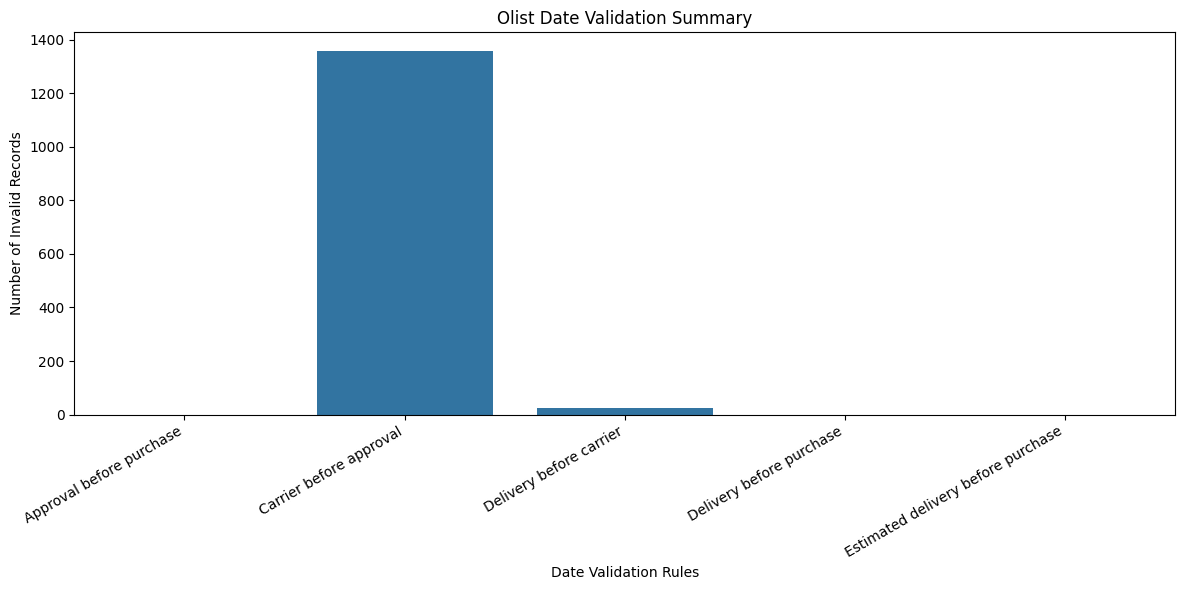

In [76]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=date_validation_summary,
    x='Validation',
    y='Invalid Records'
)

plt.title('Olist Date Validation Summary')
plt.xlabel('Date Validation Rules')
plt.ylabel('Number of Invalid Records')

plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [77]:
# STEP 31: Prepare analysis datasets

# Connect orders with customer information
customer_orders_analysis = orders_clean.merge(
    customers_clean[
        ['customer_id', 'customer_state', 'customer_city']
    ],
    on='customer_id',
    how='left'
)

# Connect order items with order information
order_items_analysis = order_items_clean.merge(
    orders_clean[
        ['order_id', 'order_purchase_timestamp']
    ],
    on='order_id',
    how='left'
)

# Connect order items with product information
product_analysis = order_items_clean.merge(
    products_clean[
        ['product_id', 'product_category_name']
    ],
    on='product_id',
    how='left'
)

print("Customer orders:", customer_orders_analysis.shape)
print("Order items analysis:", order_items_analysis.shape)
print("Product analysis:", product_analysis.shape)

Customer orders: (99441, 10)
Order items analysis: (112650, 8)
Product analysis: (112650, 8)


In [80]:
# Recreate delivery_comparison

delivery_analysis = orders_clean.dropna(
    subset=[
        'order_purchase_timestamp',
        'order_delivered_customer_date'
    ]
).copy()

delivery_comparison = delivery_analysis.dropna(
    subset=['order_estimated_delivery_date']
).copy()

# Calculate delivery performance

delivery_comparison['Delivery Performance'] = np.where(
    delivery_comparison['order_delivered_customer_date']
    <= delivery_comparison['order_estimated_delivery_date'],
    'On Time',
    'Late'
)

print("Delivery comparison created successfully!")
print("Total orders:", len(delivery_comparison))

delivery_comparison.head()

Delivery comparison created successfully!
Total orders: 96476


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,Delivery Performance
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,On Time
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,On Time
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,On Time
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,On Time
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,On Time


In [78]:
# STEP 32: Delivery analysis by state

state_delivery = customer_orders_analysis.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_purchase_timestamp',
        'order_estimated_delivery_date',
        'customer_state'
    ]
).copy()

# Calculate actual delivery time
state_delivery['Delivery Days'] = (
    state_delivery['order_delivered_customer_date']
    - state_delivery['order_purchase_timestamp']
).dt.total_seconds() / 86400

# Calculate difference between actual and estimated delivery
state_delivery['Delay Days'] = (
    state_delivery['order_delivered_customer_date']
    - state_delivery['order_estimated_delivery_date']
).dt.total_seconds() / 86400

# Summarise by state
state_performance = (
    state_delivery
    .groupby('customer_state')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Average_Delivery_Days=('Delivery Days', 'mean'),
        Average_Delay_Days=('Delay Days', 'mean')
    )
    .reset_index()
)

state_performance = state_performance.sort_values(
    'Average_Delay_Days',
    ascending=False
)

state_performance.head(10)

,customer_state,Total_Orders,Average_Delivery_Days,Average_Delay_Days
1,AL,397,24.543855,-8.032059
9,MA,717,21.572976,-8.887844
24,SE,335,21.519788,-9.328641
7,ES,1995,15.789307,-9.797109
4,BA,3256,19.335466,-10.099073
5,CE,1279,21.266579,-10.110007
11,MS,701,15.618319,-10.355558
25,SP,40495,8.761357,-10.381190
16,PI,476,19.457098,-10.629538
23,SC,3547,14.959297,-10.806692


In [81]:
# STEP 33: Monthly delivery analysis

monthly_delivery = delivery_comparison.copy()

monthly_delivery['Purchase Month'] = (
    monthly_delivery['order_purchase_timestamp']
    .dt.to_period('M').astype(str)
)

monthly_delivery['Delay Days'] = (
    monthly_delivery['order_delivered_customer_date']
    - monthly_delivery['order_estimated_delivery_date']
).dt.total_seconds() / 86400

monthly_delivery_summary = (
    monthly_delivery
    .groupby('Purchase Month')
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Average_Delay=('Delay Days', 'mean')
    )
    .reset_index()
)

monthly_delivery_summary.head(15)

,Purchase Month,Total_Orders,Average_Delay
0,2016-09,1,36.324745
1,2016-10,270,-36.059479
2,2016-12,1,-21.336991
3,2017-01,750,-26.861788
4,2017-02,1653,-18.680104
5,2017-03,2546,-11.781202
6,2017-04,2303,-12.431898
7,2017-05,3545,-12.962421
8,2017-06,3135,-12.010292
9,2017-07,3872,-11.724584


In [83]:
# STEP 34: Delivery and review analysis

review_delivery = orders_clean[
    [
        'order_id',
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
].merge(
    reviews_clean[
        ['order_id', 'review_score']
    ],
    on='order_id',
    how='inner'
)

# Remove records with missing dates or ratings
review_delivery = review_delivery.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date',
        'review_score'
    ]
).copy()

# Classify delivery performance
review_delivery['Delivery Category'] = np.where(
    review_delivery['order_delivered_customer_date']
    <= review_delivery['order_estimated_delivery_date'],
    'On Time or Early',
    'Late'
)

# Compare average review scores
review_delivery_summary = (
    review_delivery
    .groupby('Delivery Category')
    .agg(
        Total_Reviews=('review_score', 'count'),
        Average_Review=('review_score', 'mean')
    )
    .reset_index()
)

review_delivery_summary

,Delivery Category,Total_Reviews,Average_Review
0,Late,7701,2.566550
1,On Time or Early,88658,4.293578


In [84]:
# STEP 35: Product revenue concentration

product_revenue_analysis = (
    order_items_clean
    .groupby('product_id')
    .agg(
        Total_Revenue=('price', 'sum'),
        Items_Sold=('order_item_id', 'count')
    )
    .reset_index()
)

# Sort products by revenue
product_revenue_analysis = (
    product_revenue_analysis
    .sort_values('Total_Revenue', ascending=False)
    .reset_index(drop=True)
)

# Calculate cumulative revenue
product_revenue_analysis['Cumulative Revenue'] = (
    product_revenue_analysis['Total_Revenue'].cumsum()
)

# Calculate cumulative revenue percentage
total_revenue = product_revenue_analysis['Total_Revenue'].sum()

product_revenue_analysis['Cumulative Revenue %'] = (
    product_revenue_analysis['Cumulative Revenue']
    / total_revenue * 100
)

# Calculate product percentage
product_revenue_analysis['Product %'] = (
    (np.arange(len(product_revenue_analysis)) + 1)
    / len(product_revenue_analysis) * 100
)

product_revenue_analysis.head(20)


,product_id,Total_Revenue,Items_Sold,Cumulative Revenue,Cumulative Revenue %,Product %
0,bb50f2e236e5eea0100680137654686c,63885.00,195,63885.00,0.470031,0.003035
1,6cdd53843498f92890544667809f1595,54730.20,156,118615.20,0.872707,0.006070
2,d6160fb7873f184099d9bc95e30376af,48899.34,35,167514.54,1.232482,0.009104
3,d1c427060a0f73f6b889a5c7c61f2ac4,47214.51,343,214729.05,1.579861,0.012139
4,99a4788cb24856965c36a24e339b6058,43025.56,488,257754.61,1.896420,0.015174
5,3dd2a17168ec895c781a9191c1e95ad7,41082.60,274,298837.21,2.198683,0.018209
6,25c38557cf793876c5abdd5931f922db,38907.32,38,337744.53,2.484942,0.021244
7,5f504b3a1c75b73d6151be81eb05bdc9,37733.90,63,375478.43,2.762568,0.024278
8,53b36df67ebb7c41585e8d54d6772e08,37683.42,323,413161.85,3.039823,0.027313
9,aca2eb7d00ea1a7b8ebd4e68314663af,37608.90,527,450770.75,3.316529,0.030348


In [85]:
top_10_percent_count = max(
    1,
    int(np.ceil(len(product_revenue_analysis) * 0.10))
)

top_10_percent_revenue = (
    product_revenue_analysis
    .head(top_10_percent_count)['Total_Revenue']
    .sum()
)

top_10_percent_contribution = (
    top_10_percent_revenue / total_revenue * 100
)

print(
    "Revenue contribution of top 10% products:",
    round(top_10_percent_contribution, 2),
    "%"
)

Revenue contribution of top 10% products: 60.85 %


In [87]:
# FIX: Include customer_unique_id

customer_orders_analysis = orders_clean.merge(
    customers_clean[
        [
            'customer_id',
            'customer_unique_id',
            'customer_state',
            'customer_city'
        ]
    ],
    on='customer_id',
    how='left'
)

# Check columns
print(customer_orders_analysis.columns.tolist())

# Check first five rows
customer_orders_analysis.head()

['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_state', 'customer_city']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,customer_city
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,sao paulo
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,barreiras
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,vianopolis
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,sao goncalo do amarante
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,santo andre


In [88]:
# STEP 36: Customer revenue segmentation

customer_revenue_analysis = (
    customer_orders_analysis[
        ['customer_id', 'customer_unique_id']
    ]
    .merge(
        orders_clean[['order_id', 'customer_id']],
        on='customer_id',
        how='inner'
    )
    .merge(
        order_items_clean[['order_id', 'price']],
        on='order_id',
        how='inner'
    )
    .groupby('customer_unique_id')
    .agg(
        Total_Revenue=('price', 'sum'),
        Total_Orders=('order_id', 'nunique')
    )
    .reset_index()
)

# Divide customers into four revenue groups
customer_revenue_analysis['Revenue Segment'] = pd.qcut(
    customer_revenue_analysis['Total_Revenue'],
    q=4,
    labels=[
        'Low Value',
        'Medium Value',
        'High Value',
        'Very High Value'
    ],
    duplicates='drop'
)

customer_revenue_summary = (
    customer_revenue_analysis
    .groupby('Revenue Segment', observed=True)
    .agg(
        Total_Customers=('customer_unique_id', 'count'),
        Average_Revenue=('Total_Revenue', 'mean'),
        Total_Revenue=('Total_Revenue', 'sum')
    )
    .reset_index()
)

customer_revenue_summary

,Revenue Segment,Total_Customers,Average_Revenue,Total_Revenue
0,Low Value,23984,29.236924,701218.38
1,Medium Value,24869,66.777989,1660701.82
2,High Value,22731,119.522407,2716863.83
3,Very High Value,23836,357.142963,8512859.67


In [89]:
# STEP 37: Detect price outliers

Q1 = order_items_clean['price'].quantile(0.25)

Q3 = order_items_clean['price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

price_outliers = order_items_clean[
    (order_items_clean['price'] < lower_limit) |
    (order_items_clean['price'] > upper_limit)
]

print("First Quartile:", Q1)
print("Third Quartile:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Price Outliers:", len(price_outliers))

First Quartile: 39.9
Third Quartile: 134.9
IQR: 95.0
Lower Limit: -102.6
Upper Limit: 277.4
Number of Price Outliers: 8427


In [90]:
price_outliers[
    ['order_id', 'product_id', 'price']
].head(20)

,order_id,product_id,price
7,000576fe39319847cbb9d288c5617fa6,557d850972a7d6f792fd18ae1400d9b6,810.00
16,0009c9a17f916a706d71784483a5d643,3f27ac8e699df3d300ec4a5d8c5cf0b2,639.00
26,0011d82c4b53e22e84023405fb467e57,c389f712c4b4510bc997cee93e8b1a28,289.00
30,00137e170939bba5a3134e2386413108,672e757f331900b9deea127a2a7b79fd,397.00
39,0017afd5076e074a48f1f1a4c7bac9c5,fe59a1e006df3ac42bf0ceb876d70969,809.10
61,0025c5d1a8ca53a240ec2634bb4492ea,35537536ed2b4c561b4018bf3abf54e0,390.00
65,00275bce676303c3bfd7292aefdfa223,6490b9f63b0b595e1c1402b46b0f50ad,279.90
70,0029c5db35ef291ce99d1262012e7daa,7614c62b86a81021243e438cfde78ccc,492.75
99,0036887767dea4bd43b1a88cd0d9477a,3a264b078bf20e98f315ff65c23fa263,399.99
158,006127b8b9a1681a982313ed7129c3c0,f819f0c84a64f02d3a5606ca95edd272,540.00


In [91]:
# STEP 38: Correlation analysis

correlation_data = order_items_clean[
    ['price', 'freight_value']
].copy()

correlation_data['Delivery Days'] = (
    order_items_analysis['order_purchase_timestamp']
)

print(correlation_data.head())

    price  freight_value       Delivery Days
0   58.90          13.29 2017-09-13 08:59:02
1  239.90          19.93 2017-04-26 10:53:06
2  199.00          17.87 2018-01-14 14:33:31
3   12.99          12.79 2018-08-08 10:00:35
4  199.90          18.14 2017-02-04 13:57:51


In [92]:
# Prepare item-level delivery analysis

correlation_data = order_items_analysis.merge(
    orders_clean[
        [
            'order_id',
            'order_delivered_customer_date'
        ]
    ],
    on='order_id',
        how='left'
)

correlation_data['Delivery Days'] = (
    correlation_data['order_delivered_customer_date']
    - correlation_data['order_purchase_timestamp']
).dt.total_seconds() / 86400

correlation_data = correlation_data[
    [
        'price',
        'freight_value',
        'Delivery Days'
    ]
].dropna()

correlation_matrix = correlation_data.corr()

correlation_matrix

,price,freight_value,Delivery Days
price,1.000000,0.412718,0.062390
freight_value,0.412718,1.000000,0.214687
Delivery Days,0.062390,0.214687,1.000000


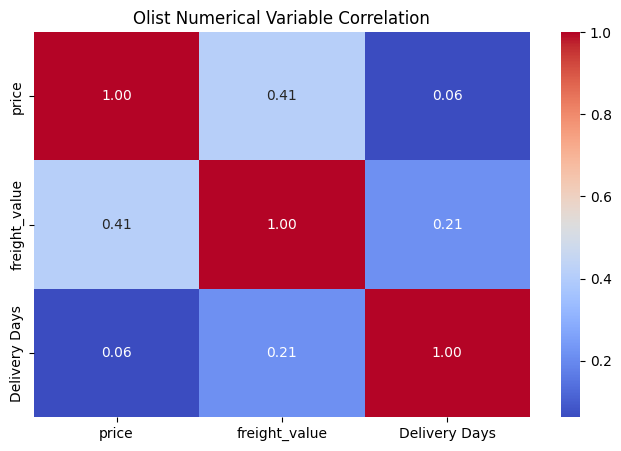

In [93]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Olist Numerical Variable Correlation')

plt.show()

In [95]:
# FIX: Recreate monthly_revenue

order_revenue = order_items_clean.merge(
    orders_clean[
        ['order_id', 'order_purchase_timestamp']
    ],
    on='order_id',
    how='left'
)

order_revenue['purchase_month'] = (
    order_revenue['order_purchase_timestamp']
    .dt.to_period('M').astype(str)
)

monthly_revenue = (
    order_revenue
    .groupby('purchase_month')['price']
    .sum()
    .reset_index(name='Product Revenue')
)

print("Monthly revenue dataset created successfully!")

monthly_revenue.head(15)

Monthly revenue dataset created successfully!


,purchase_month,Product Revenue
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02
5,2017-03,374344.30
6,2017-04,359927.23
7,2017-05,506071.14
8,2017-06,433038.60
9,2017-07,498031.48


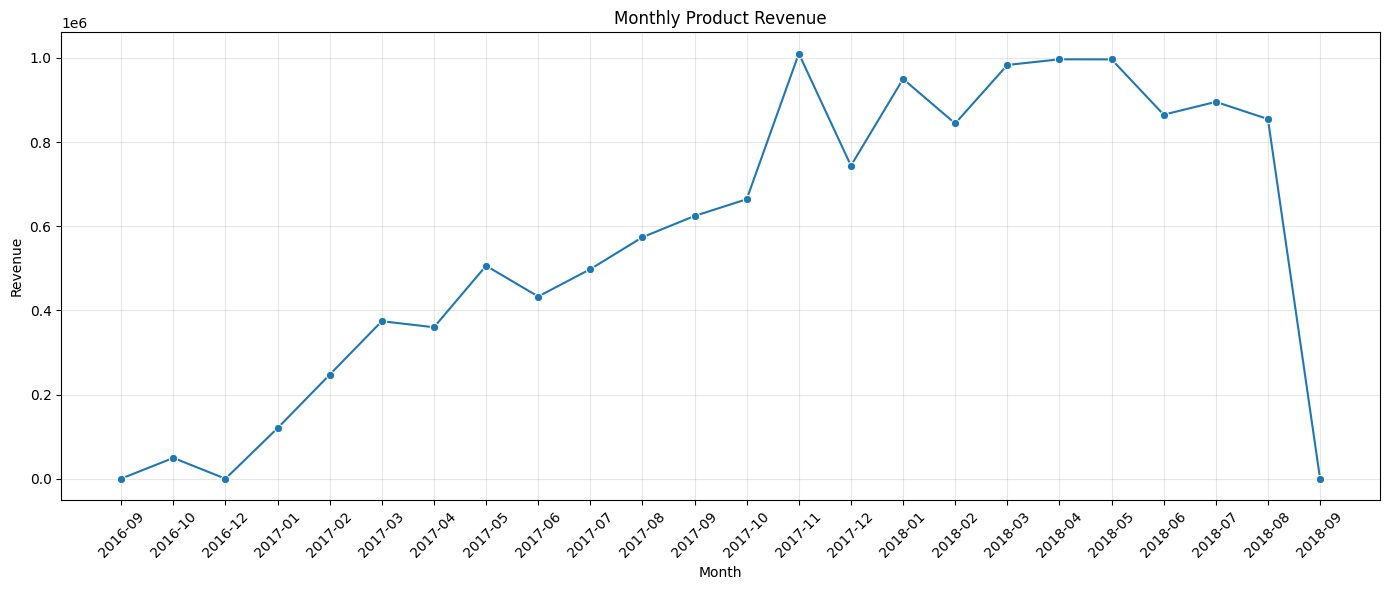

In [96]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x='purchase_month',
    y='Product Revenue',
    marker='o'
)

plt.title('Monthly Product Revenue')

plt.xlabel('Month')

plt.ylabel('Revenue')

plt.xticks(rotation=45)

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [98]:
# FIX: Recreate category_revenue

product_analysis = order_items_clean.merge(
    products_clean[
        ['product_id', 'product_category_name']
    ],
    on='product_id',
    how='left'
)

category_revenue = (
    product_analysis
    .groupby('product_category_name')['price']
    .sum()
    .reset_index(name='Product Revenue')
    .sort_values(
        'Product Revenue',
        ascending=False
    )
)

print("Category revenue created successfully!")

category_revenue.head(10)

Category revenue created successfully!


,product_category_name,Product Revenue
11,beleza_saude,1258681.34
66,relogios_presentes,1205005.68
13,cama_mesa_banho,1036988.68
32,esporte_lazer,988048.97
44,informatica_acessorios,911954.32
54,moveis_decoracao,729762.49
26,cool_stuff,635290.85
72,utilidades_domesticas,632248.66
8,automotivo,592720.11
40,ferramentas_jardim,485256.46


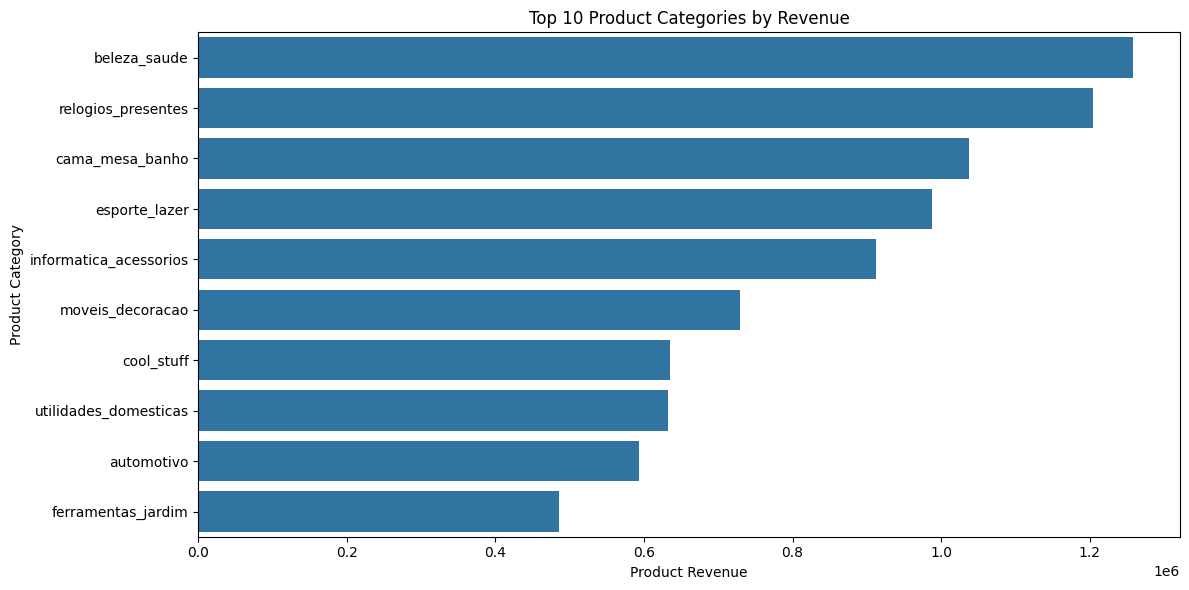

In [99]:
top_categories = category_revenue.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x='Product Revenue',
    y='product_category_name'
)

plt.title('Top 10 Product Categories by Revenue')

plt.xlabel('Product Revenue')

plt.ylabel('Product Category')

plt.tight_layout()

plt.show()

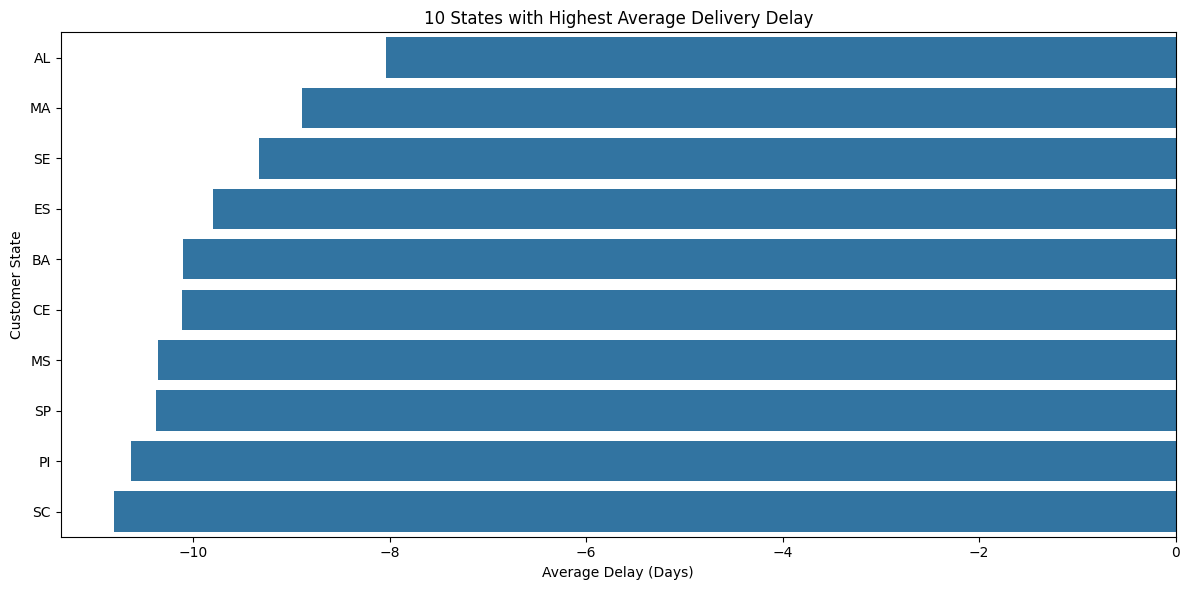

In [100]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=state_performance.sort_values(
        'Average_Delay_Days',
        ascending=False
    ).head(10),
    x='Average_Delay_Days',
    y='customer_state'
)

plt.title('10 States with Highest Average Delivery Delay')

plt.xlabel('Average Delay (Days)')

plt.ylabel('Customer State')

plt.tight_layout()

plt.show()

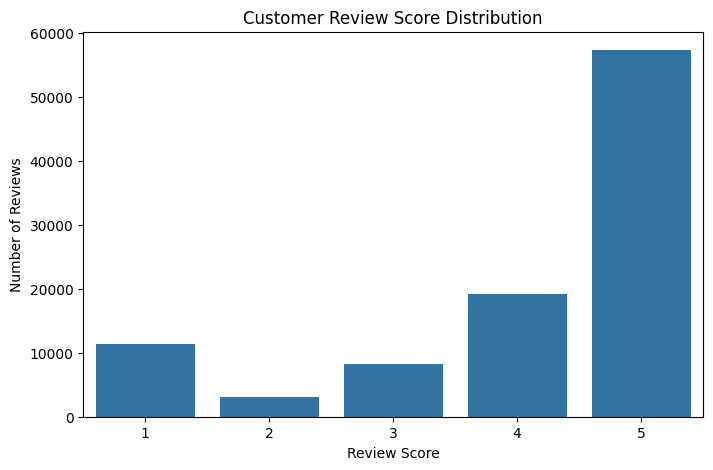

In [101]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews_clean,
    x='review_score'
)

plt.title('Customer Review Score Distribution')

plt.xlabel('Review Score')

plt.ylabel('Number of Reviews')

plt.show()

In [102]:
os.makedirs(processed_path, exist_ok=True)


In [103]:
# STEP 40: Export analysis-ready datasets

exports = {
    'monthly_revenue.csv': monthly_revenue,
    'category_revenue.csv': category_revenue,
    'state_delivery_performance.csv': state_performance,
    'review_delivery_analysis.csv': review_delivery_summary,
    'customer_revenue_segments.csv': customer_revenue_summary,
    'product_revenue_analysis.csv': product_revenue_analysis,
    'monthly_delivery_performance.csv': monthly_delivery_summary
}

for filename, df in exports.items():

    df.to_csv(
        os.path.join(processed_path, filename),
        index=False
    )

    print("Exported:", filename)

Exported: monthly_revenue.csv
Exported: category_revenue.csv
Exported: state_delivery_performance.csv
Exported: review_delivery_analysis.csv
Exported: customer_revenue_segments.csv
Exported: product_revenue_analysis.csv
Exported: monthly_delivery_performance.csv
